In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from astropy.cosmology import FlatLambdaCDM
from lenstronomy.Cosmo.lens_cosmo import LensCosmo
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.Util.param_util import phi_q2_ellipticity, shear_polar2cartesian

In [5]:
# Cosmology parameters from Ballard et al. (2024)
z_lens = 0.222
z_source = 0.609
cosmo = FlatLambdaCDM(H0=67.77, Om0=0.307)
lens_cosmo = LensCosmo(z_lens=z_lens, z_source=z_source, cosmo=cosmo)

# Same perturber position for BH and tNFW
perturber_x = -1.111
perturber_y = 1.022

# Single-plane I-band reference tNFW parameters, numbers from Ballard et al. (2024)
M200_reference = 10**10.834  # Msun 
c_reference = 10**1.979
r_trunc = 10**(-0.446)     # arcsec

# Sample tNFW concentrations, including the reference one
concentrations = np.unique(np.append(np.geomspace(5.0, 300, 25), c_reference))

kwargs_single_band = {
    "pixel_scale": 0.05,         # arcsec / pixel
    "exposure_time": 524.0,    # seconds per exposure
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,
    "ccd_gain": 2.0,
    "sky_brightness": 22.0,
    "num_exposures": 4,
    "seeing": 0.10,             # arcsec (Gaussian PSF FWHM)
    "psf_type": "GAUSSIAN"}


numpix = 120
supersampling = 3

phi = np.deg2rad(-70.113)
e1, e2 = phi_q2_ellipticity(phi, 0.960)
shear_angle = np.deg2rad(-23.243)
gamma1, gamma2 = shear_polar2cartesian(shear_angle, 0.107)

kwargs_epl = {
    "theta_E": 1.397,
    "gamma": 2.123,
    "e1": e1,
    "e2": e2,
    "center_x": 0.031,
    "center_y": 0.047}

kwargs_shear = {"gamma1": gamma1, "gamma2": gamma2}
kwargs_main_lens = [kwargs_epl, kwargs_shear]

# Background source-light model
kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    "center_x": 0.08,
    "center_y": -0.03}]

print(f"Reference concentration: c = {c_reference:.3f}")
print(f"Nmumber of trials: {len(concentrations)}")

Reference concentration: c = 95.280
Nmumber of trials: 26


In [11]:
# Integrate tNFW mass 
def tnfw_integrand(x, tau):
    nfw_term = x / (1.0 + x)**2
    truncation_term = tau**2 / (x**2 + tau**2)
    return nfw_term * truncation_term


def tnfw_total_mass(M200, c):
    # Scale radius returned in [arcsec]
    rs_angle, _ = lens_cosmo.nfw_physical2angle(M=M200, c=c)
    tau = r_trunc / rs_angle
    f_c = np.log(1.0 + c) - c / (1.0 + c)
    integral, estimated_error = quad(tnfw_integrand, 0.0, np.inf, args=(tau,))
    return M200 * integral / f_c


# Get the reference mass
M_target = tnfw_total_mass(M200_reference, c_reference)

# Calculate the relative mass difference
def mass_match_error(log10_M200, c, target_mass):
    trial_M200 = 10.0**log10_M200
    trial_total_mass = tnfw_total_mass(trial_M200, c)
    return trial_total_mass / target_mass - 1.0

# Convert input refernce total mass with different c_200 to M_200 for the simulation
def M200_for_target_mass(c, target_mass):
    # Range searching over
    low_logM, high_logM = 6.0, 14.0
    low_error = mass_match_error(low_logM, c, target_mass)
    high_error = mass_match_error(high_logM, c, target_mass)
    # Use brentq to try different values of log10_M200 until trial_total_mass matches target_mass
    # brentq takes fucntion, lower bound, upper bound of search interval, arguments passed to function that remain fixed
    log10_M200 = brentq(mass_match_error, low_logM, high_logM, args=(c, target_mass))
    return 10.0**log10_M200


# Check that the fucntions reproduces the reference case
M200_check = M200_for_target_mass(c_reference, M_target)
print(f"Matched target mass = {M_target:.5e} Msun")
print(f"Reference M200 = {M200_reference:.5e} Msun")
print(f"Recovered M200 at reference c = {M200_check:.5e} Msun")
print(f"Relative error in recovered M200 = {abs(M200_check / M200_reference) - 1.0}")

Matched target mass = 8.36235e+09 Msun
Reference M200 = 6.82339e+10 Msun
Recovered M200 at reference c = 6.82339e+10 Msun
Relative error in recovered M200 = 6.135092434078615e-13


In [15]:
kwargs_model_bh = {
    "lens_model_list": ["EPL", "SHEAR", "POINT_MASS"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}
kwargs_model_nfw = {
    "lens_model_list": ["EPL", "SHEAR", "TNFW"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}

sim_bh = SimAPI(numpix=numpix, kwargs_single_band=kwargs_single_band,
                kwargs_model=kwargs_model_bh)
sim_nfw = SimAPI(numpix=numpix, kwargs_single_band=kwargs_single_band,
                 kwargs_model=kwargs_model_nfw)

model_bh = sim_bh.image_model_class(
    kwargs_numerics={"supersampling_factor": supersampling})
model_nfw = sim_nfw.image_model_class(
    kwargs_numerics={"supersampling_factor": supersampling})

_, kwargs_source, _ = sim_nfw.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)

point_mass_at_1arcsec = lens_cosmo.mass_in_theta_E(1.0)
theta_E_bh = np.sqrt(M_target / point_mass_at_1arcsec)
kwargs_bh = {
    "theta_E": theta_E_bh,
    "center_x": perturber_x,
    "center_y": perturber_y}

# Baseline images without bh and tNFW
kwargs_bh_off = {
    "theta_E": 0.0,
    "center_x": perturber_x,
    "center_y": perturber_y}
kwargs_nfw_off = {
    "Rs": 1.0,
    "alpha_Rs": 0.0,
    "r_trunc": r_trunc,
    "center_x": perturber_x,
    "center_y": perturber_y}

baseline_bh = model_bh.image(
    kwargs_lens=kwargs_main_lens + [kwargs_bh_off],
    kwargs_source=kwargs_source)
baseline_nfw = model_nfw.image(
    kwargs_lens=kwargs_main_lens + [kwargs_nfw_off],
    kwargs_source=kwargs_source)

image_bh = model_bh.image(
    kwargs_lens=kwargs_main_lens + [kwargs_bh],
    kwargs_source=kwargs_source)

bh_residual = image_bh - baseline_bh
rms_bh_baseline = np.sqrt(np.mean(bh_residual**2))

print(f"BH total mass (reference mass): {M_target:.4e} Msun")
print(f"BH vs baseline RMS: {rms_bh_baseline:.6g}")


BH total mass (reference mass): 8.3623e+09 Msun
BH vs baseline RMS: 0.0213556


In [17]:
saved_cases = {}
concentration_values = []
rms_direct = []
rms_nfw_baseline = []
rms_bh_baseline_values = []
M200_solved = []

for c_trial in concentrations:
    M200_trial = M200_for_target_mass(c_trial, M_target)
    actual_mass = tnfw_total_mass(M200_trial, c_trial)

    rs_angle, alpha_Rs = lens_cosmo.nfw_physical2angle(
        M=M200_trial, c=c_trial)
    kwargs_tnfw = {
        "Rs": rs_angle,
        "alpha_Rs": alpha_Rs,
        "r_trunc": r_trunc,
        "center_x": perturber_x,
        "center_y": perturber_y}

    image_nfw = model_nfw.image(
        kwargs_lens=kwargs_main_lens + [kwargs_tnfw],
        kwargs_source=kwargs_source)

    difference = image_bh - image_nfw
    residual_nfw = image_nfw - baseline_nfw

    direct_rms = np.sqrt(np.mean(difference**2))
    nfw_rms = np.sqrt(np.mean(residual_nfw**2))

    saved_cases[float(c_trial)] = {
        "c": float(c_trial),
        "M200": M200_trial,
        "M_total": actual_mass,
        "kwargs_tnfw": kwargs_tnfw.copy(),
        "image_bh": image_bh.copy(),
        "image_nfw": image_nfw.copy(),
        "baseline": baseline_bh.copy(),
        "residual_bh": bh_residual.copy(),
        "residual_nfw": residual_nfw.copy(),
        "difference": difference.copy(),
        "rms_direct": direct_rms,
        "rms_nfw_baseline": nfw_rms}
    
    concentration_values.append(float(c_trial))
    M200_solved.append(M200_trial)
    rms_direct.append(direct_rms)
    rms_nfw_baseline.append(nfw_rms)
    rms_bh_baseline_values.append(rms_bh_baseline)

    print(f"c={c_trial:7.2f} | M200={M200_trial:.3e} | "
          f"M_total={actual_mass:.3e} | BH-tNFW RMS={direct_rms:.6g}")

concentration_values = np.array(concentration_values)
rms_direct = np.array(rms_direct)
rms_nfw_baseline = np.array(rms_nfw_baseline)
M200_solved = np.array(M200_solved)


c=   5.00 | M200=1.040e+13 | M_total=8.362e+09 | BH-tNFW RMS=0.0167151
c=   5.93 | M200=7.067e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.016374
c=   7.03 | M200=4.800e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.0159972
c=   8.34 | M200=3.272e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.0155836
c=   9.89 | M200=2.245e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.0151333
c=  11.73 | M200=1.555e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.0146478
c=  13.92 | M200=1.091e+12 | M_total=8.362e+09 | BH-tNFW RMS=0.0141294
c=  16.50 | M200=7.770e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0135822
c=  19.57 | M200=5.626e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0130114
c=  23.22 | M200=4.148e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0124236
c=  27.53 | M200=3.117e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0118265
c=  32.66 | M200=2.388e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0112287
c=  38.73 | M200=1.866e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0106395
c=  45.93 | M200=1.486e+11 | M_total=8.362e+09 | BH-tNFW RMS=0.0100691
c=  54.

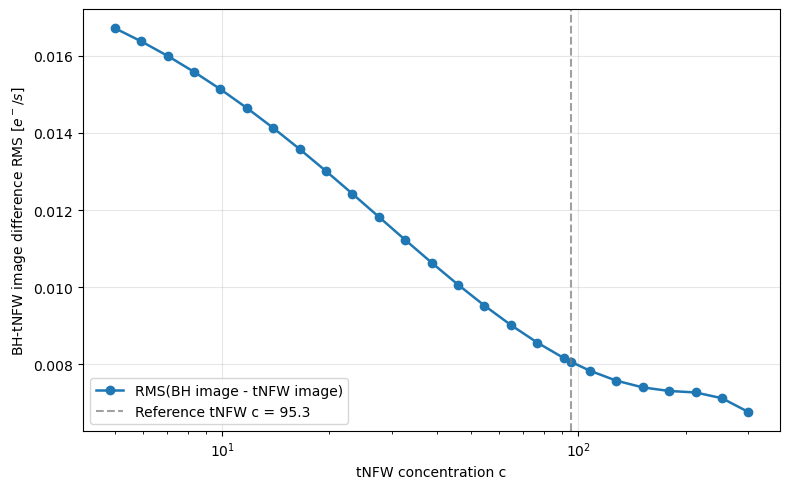

Smallest sampled difference: c = 300, RMS = 0.00676942


In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(concentration_values, rms_direct, marker="o", linewidth=1.8,
        label="RMS(BH image - tNFW image)")
ax.axvline(c_reference, color="gray", linestyle="--", alpha=0.75,
           label=f"Reference tNFW c = {c_reference:.1f}")

ax.set_xscale("log")
ax.set_xlabel("tNFW concentration c")
ax.set_ylabel("BH-tNFW image difference RMS [$e^-/s$]")
ax.grid(alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.savefig("bh_tnfw_difference_vs_concentration.png", dpi=300, bbox_inches="tight")
plt.show()

best_index = np.argmin(rms_direct)
print(f"Smallest sampled difference: c = {concentration_values[best_index]:.3g}, "
      f"RMS = {rms_direct[best_index]:.6g}")



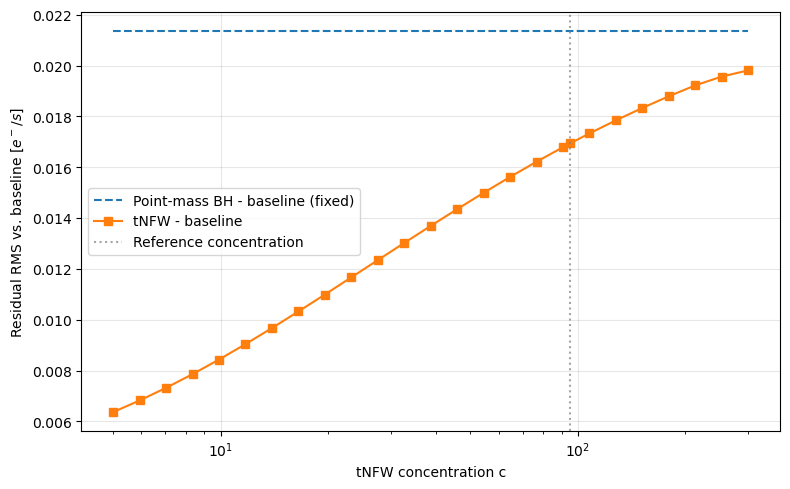

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(concentration_values, rms_bh_baseline_values,
        label="Point-mass BH - baseline (fixed)", linestyle="--")
ax.plot(concentration_values, rms_nfw_baseline,
        label="tNFW - baseline", marker="s", linewidth=1.5)
ax.axvline(c_reference, color="gray", linestyle=":", alpha=0.7,
           label="Reference concentration")

ax.set_xscale("log")
ax.set_xlabel("tNFW concentration c")
ax.set_ylabel("Residual RMS vs. baseline [$e^-/s$]")
# ax.set_title("Perturbation strength vs. tNFW concentration")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("bh_tnfw_strength_vs_concentration.png", dpi=300, bbox_inches="tight")
plt.show()
